# Лабораторная работа №2. Виртуальный датчик


## 0. Импорты и настройки

In [1]:
import os
import time
from pathlib import Path

CANDIDATES = [
    Path.cwd(),
    Path("/Users/dmitry/Desktop/project/predective_analytic/lab2"),
]
BASE = next(p for p in CANDIDATES if (p / "data_train.csv").exists())
os.environ["MPLCONFIGDIR"] = str(BASE / ".cache" / "mpl")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import statsmodels.api as sm
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

In [2]:
SEED = 7
DENSE = [f"telemetry_{i}" for i in range(12)]
SLOW = [f"telemetry_{i}" for i in range(12, 16)]
SENSORS = DENSE + SLOW
LAGS = (15, 60, 120)
LAB_DELAY_MIN = 15
LAB_MAX_AGE_MIN = 6 * 60
ZERO_CHANNELS = ["telemetry_1", "telemetry_3", "telemetry_4", "telemetry_6"]
ALPHA_GRID = [0.3, 1, 3, 10, 30, 100, 300, 1000]

print("каталог данных:", BASE)

каталог данных: /Users/dmitry/Desktop/project/predective_analytic/lab2


## 0. Загрузка

In [3]:
def read_telemetry(path: Path) -> pd.DataFrame:
    # Одна минута иногда записана дважды. Беру среднее.
    frame = pd.read_csv(path, parse_dates=["datetime"])
    return frame.groupby("datetime", sort=True)[SENSORS].mean()


def read_target(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    frame.columns = ["datetime", "target"]
    frame["datetime"] = pd.to_datetime(frame["datetime"])
    return frame.sort_values("datetime").drop_duplicates("datetime").reset_index(drop=True)

In [4]:
def duplicate_report(path: Path) -> None:
    frame = pd.read_csv(path, parse_dates=["datetime"])
    duplicated = frame[frame["datetime"].duplicated(keep=False)]
    if duplicated.empty:
        print(path.name, "повторов нет")
        return
    spread = duplicated.groupby("datetime")[SENSORS].max() - duplicated.groupby("datetime")[SENSORS].min()
    conflicts = int((spread.max(axis=1) > 1e-8).sum())
    print(
        f"{path.name}: строк {len(frame)}, повторных меток {duplicated['datetime'].nunique()}, "
        f"из них с расхождением значений {conflicts}, "
        f"максимальный размах {spread.max().max():.4f}"
    )


duplicate_report(BASE / "data_train.csv")
duplicate_report(BASE / "data_test_small.csv")

data_train.csv: строк 319546, повторных меток 222, из них с расхождением значений 1, максимальный размах 0.2400
data_test_small.csv: строк 39943, повторных меток 28, из них с расхождением значений 0, максимальный размах 0.0000


In [5]:
train_tel_raw = read_telemetry(BASE / "data_train.csv")
test_tel_raw = read_telemetry(BASE / "data_test_small.csv")
train_target = read_target(BASE / "target_train.csv")
test_target = read_target(BASE / "target_test_small.csv")

overlap = train_tel_raw.index.intersection(test_tel_raw.index)
print("общих минут у обучения и теста:", len(overlap))
print("обучение, телеметрия:", train_tel_raw.index.min(), "→", train_tel_raw.index.max(), "минут", len(train_tel_raw))
print("обучение, лаборатория:", train_target["datetime"].min(), "→", train_target["datetime"].max(), "проб", len(train_target))
print("тест, телеметрия:", test_tel_raw.index.min(), "→", test_tel_raw.index.max(), "минут", len(test_tel_raw))
print("тест, лаборатория:", test_target["datetime"].min(), "→", test_target["datetime"].max(), "проб", len(test_target))
assert train_target["datetime"].max() < test_target["datetime"].min()

общих минут у обучения и теста: 0
обучение, телеметрия: 2019-03-01 00:01:00 → 2019-10-07 19:58:00 минут 317998
обучение, лаборатория: 2019-03-13 17:00:00 → 2019-10-07 21:00:00 проб 1773
тест, телеметрия: 2019-10-07 19:59:00 → 2019-11-04 10:25:00 минут 39747
тест, лаборатория: 2019-10-07 23:00:00 → 2019-11-04 09:00:00 проб 318


## 2.1. Разведка данных

Телеметрия обучения кончается 7 октября в 19:58, а последняя обучающая проба стоит на 21:00. Минуты с 19:59 уже в тестовом файле. Это разрез файлов: 19:58 и 19:59 идут подряд. Признак в минуту `t` смотрит только назад. Тестовые лабораторные значения в разведке не использую.

In [6]:
telemetry = pd.concat([train_tel_raw, test_tel_raw]).sort_index()
telemetry = telemetry[~telemetry.index.duplicated(keep="first")]
full_index = pd.date_range(telemetry.index.min(), telemetry.index.max(), freq="min")
missing_minutes = len(full_index) - telemetry.index.nunique()
print(f"минут в сплошной сетке: {len(full_index)}, отсутствующих меток: {missing_minutes}")

# Дырки длиннее 2 минут не заполняю.
telemetry = telemetry.reindex(full_index)
telemetry.index.name = "datetime"
gaps_before = telemetry[DENSE].isna().sum()
telemetry[DENSE] = telemetry[DENSE].interpolate(method="time", limit=2)
filled_short_gaps = int((gaps_before - telemetry[DENSE].isna().sum()).sum())
print(f"коротких дыр (не длиннее 2 минут), заполненных по времени: {filled_short_gaps}")

минут в сплошной сетке: 357745, отсутствующих меток: 0
коротких дыр (не длиннее 2 минут), заполненных по времени: 208


In [7]:
# Редкие каналы: держу последнее значение и не подглядываю в будущее.
telemetry[SLOW] = telemetry[SLOW].ffill()

train_end = train_tel_raw.index.max()
eda_tel = telemetry.loc[:train_end]
eda_target = train_target.copy()
print("разведка телеметрии до", eda_tel.index.max())
print("пропуски после очистки, доля по каналам:")
print(eda_tel[SENSORS].isna().mean().round(4).to_string())

разведка телеметрии до 2019-10-07 19:58:00
пропуски после очистки, доля по каналам:
telemetry_0     0.0000
telemetry_1     0.0000
telemetry_2     0.0000
telemetry_3     0.0000
telemetry_4     0.0004
telemetry_5     0.0000
telemetry_6     0.0000
telemetry_7     0.0000
telemetry_8     0.0000
telemetry_9     0.0000
telemetry_10    0.0000
telemetry_11    0.0000
telemetry_12    0.0004
telemetry_13    0.0004
telemetry_14    0.0004
telemetry_15    0.0004


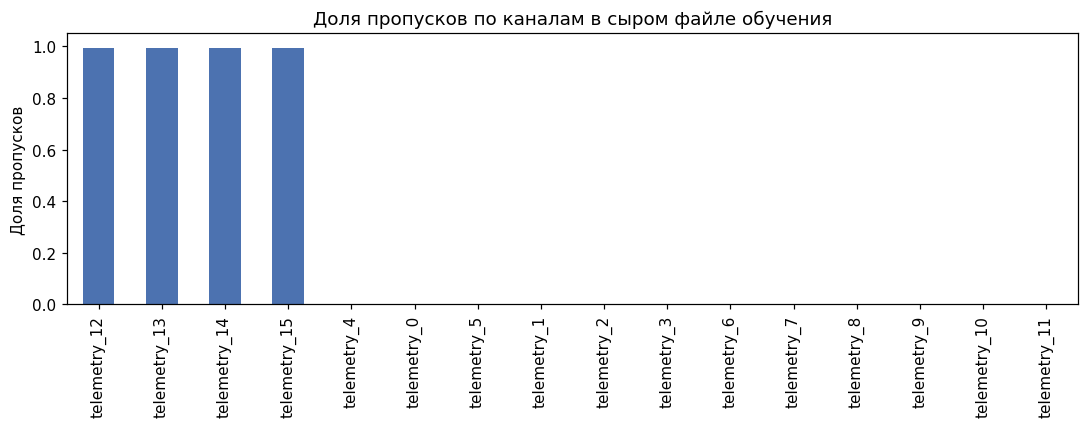

In [8]:
raw_train = pd.read_csv(BASE / "data_train.csv", parse_dates=["datetime"])
missing_rate = raw_train[SENSORS].isna().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
missing_rate.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_ylabel("Доля пропусков")
ax.set_xlabel("")
ax.set_title("Доля пропусков по каналам в сыром файле обучения")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [9]:
slow_times = raw_train.loc[raw_train[SLOW].notna().any(axis=1), "datetime"]
slow_step = slow_times.sort_values().drop_duplicates().diff().dt.total_seconds() / 60
print("Каналы 12–15, число сырых минут с хотя бы одним значением:", slow_times.nunique())
print("Минута внутри часа:", sorted(slow_times.dt.minute.unique().tolist()))
print("Часы, где они вообще появляются:", sorted(slow_times.dt.hour.unique().tolist()))
print(
    "Шаг между такими минутами, медиана и доля шага ровно 120 мин:",
    float(slow_step.median()),
    float((slow_step == 120).mean()),
)

Каналы 12–15, число сырых минут с хотя бы одним значением: 2097
Минута внутри часа: [0]
Часы, где они вообще появляются: [0, 2, 4, 6, 8, 10, 12, 14, 16, 17, 18, 20, 22]
Шаг между такими минутами, медиана и доля шага ровно 120 мин: 120.0 0.9876013352408202


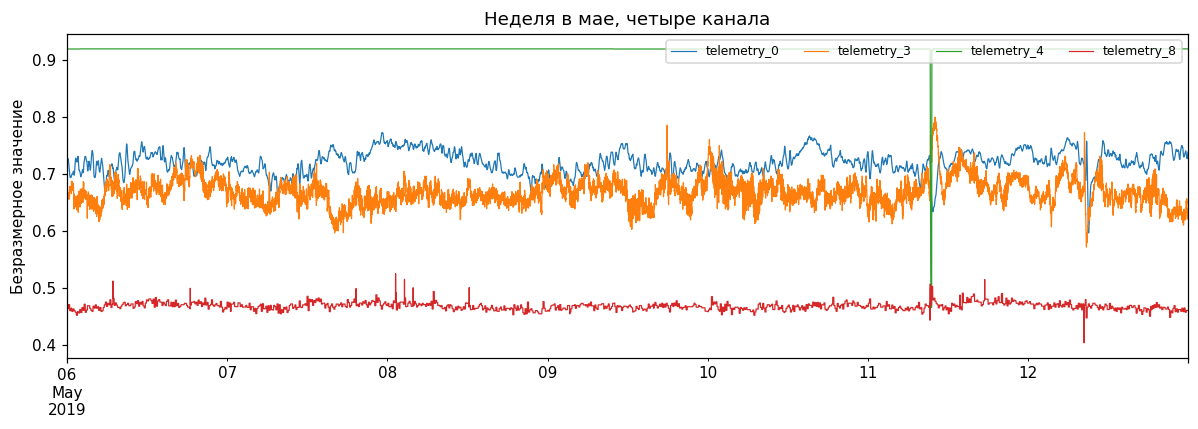

In [10]:
week = eda_tel.loc["2019-05-06":"2019-05-12", ["telemetry_0", "telemetry_3", "telemetry_4", "telemetry_8"]]
fig, ax = plt.subplots(figsize=(11, 4))
week.plot(ax=ax, lw=0.8)
ax.set_title("Неделя в мае, четыре канала")
ax.set_ylabel("Безразмерное значение")
ax.set_xlabel("")
ax.legend(loc="upper right", ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

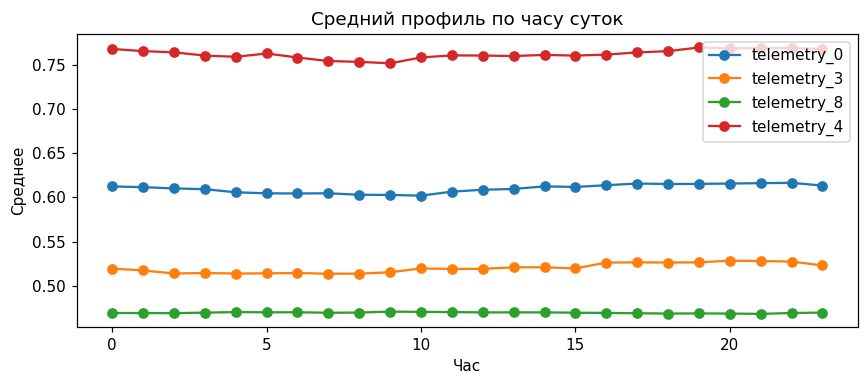

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
hour_profile = eda_tel[DENSE].groupby(eda_tel.index.hour).mean()
hour_profile[["telemetry_0", "telemetry_3", "telemetry_8", "telemetry_4"]].plot(ax=ax, marker="o")
ax.set_title("Средний профиль по часу суток")
ax.set_xlabel("Час")
ax.set_ylabel("Среднее")
plt.tight_layout()
plt.show()

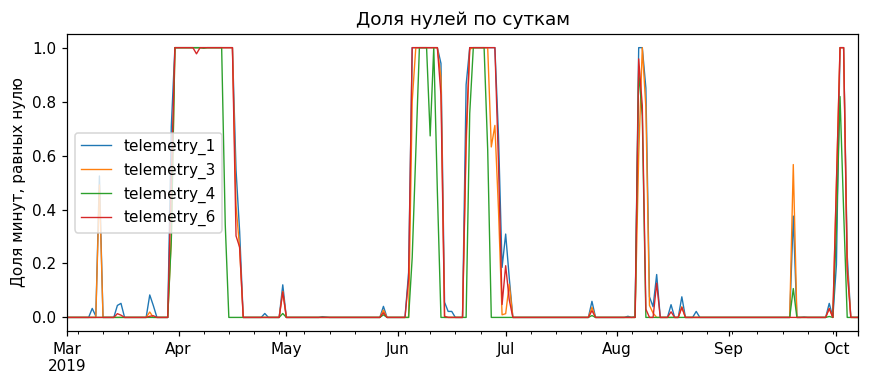

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
zero_share = (eda_tel[ZERO_CHANNELS] == 0).resample("D").mean()
zero_share.plot(ax=ax, lw=0.9)
ax.set_title("Доля нулей по суткам")
ax.set_ylabel("Доля минут, равных нулю")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [13]:
def iqr_outlier_share(column: str) -> float:
    series = raw_train[column].dropna()
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    if iqr == 0:
        return float((series != q1).mean())
    outside = (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)
    return float(outside.mean())


desc = raw_train[SENSORS].describe().T
desc["nunique_raw"] = raw_train[SENSORS].nunique()
desc["zero_share"] = [(raw_train[col].dropna() == 0).mean() for col in SENSORS]
desc["iqr_outlier_share"] = [iqr_outlier_share(col) for col in SENSORS]
print(desc[["min", "50%", "max", "std", "nunique_raw", "zero_share", "iqr_outlier_share"]].round(3).to_string())

                min    50%    max    std  nunique_raw  zero_share  iqr_outlier_share
telemetry_0   0.003  0.739  1.000  0.276         2419       0.000              0.213
telemetry_1   0.000  0.486  0.611  0.198        59697       0.204              0.226
telemetry_2   0.032  0.296  1.000  0.088         1695       0.000              0.213
telemetry_3   0.000  0.639  1.000  0.259       229085       0.188              0.206
telemetry_4   0.000  0.919  1.000  0.326         2031       0.133              0.214
telemetry_5   0.000  0.830  1.000  0.284         3177       0.000              0.180
telemetry_6   0.000  0.749  1.000  0.300          961       0.188              0.221
telemetry_7   0.021  0.411  1.000  0.253         1293       0.000              0.220
telemetry_8   0.344  0.468  1.000  0.024          557       0.000              0.013
telemetry_9   0.000  0.582  1.000  0.255         3453       0.000              0.000
telemetry_10  0.000  0.598  1.000  0.249         3485       0.003

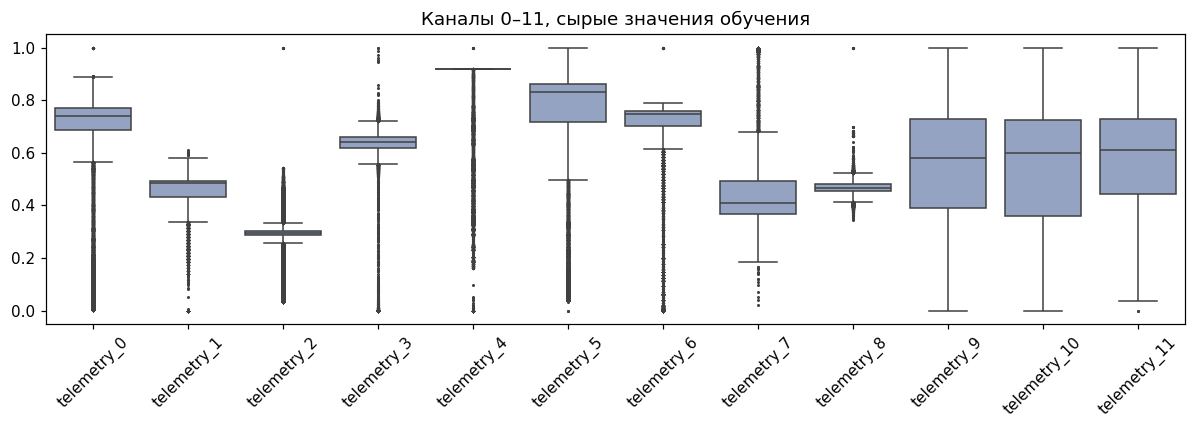

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=raw_train[DENSE], ax=ax, fliersize=1, color="#8DA0CB")
ax.set_title("Каналы 0–11, сырые значения обучения")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

In [15]:
lab = eda_target.copy()
step_min = lab["datetime"].diff().dt.total_seconds() / 60
print(lab["target"].describe().round(4).to_string())
print("нулей у цели:", int((lab["target"] == 0).sum()))
print("пробы ровно в ноль минут:", float((lab["datetime"].dt.minute == 0).mean()))
print("шаг между пробами, минуты:")
print(step_min.describe().round(1).to_string())
print("самые частые шаги:")
print(step_min.round().value_counts().head(6).to_string())

long_gaps = lab.loc[step_min > LAB_MAX_AGE_MIN, ["datetime"]].copy()
long_gaps["gap_h"] = step_min[step_min > LAB_MAX_AGE_MIN].to_numpy() / 60
print("пропуски дольше 6 часов, конец паузы и длина в часах:")
print(long_gaps.to_string(index=False))

count    1773.0000
mean        0.2543
std         0.0922
min         0.0000
25%         0.1753
50%         0.2474
75%         0.3144
max         0.7165
нулей у цели: 1
пробы ровно в ноль минут: 0.9994359842075579
шаг между пробами, минуты:
count     1772.0
mean       169.2
std        784.1
min         60.0
25%        120.0
50%        120.0
75%        120.0
max      26430.0
самые частые шаги:
datetime
120.0      1570
240.0       184
60.0          4
420.0         2
90.0          1
26430.0       1
пропуски дольше 6 часов, конец паузы и длина в часах:
           datetime  gap_h
2019-04-17 15:00:00  440.5
2019-04-18 10:00:00   11.0
2019-04-29 21:00:00   14.0
2019-06-14 01:00:00  222.0
2019-06-29 17:00:00  230.0
2019-06-30 10:00:00    7.0
2019-07-02 05:00:00    7.0
2019-08-04 09:00:00   10.0
2019-08-10 09:00:00   74.0
2019-09-19 21:00:00   20.0
2019-10-04 07:00:00   68.0


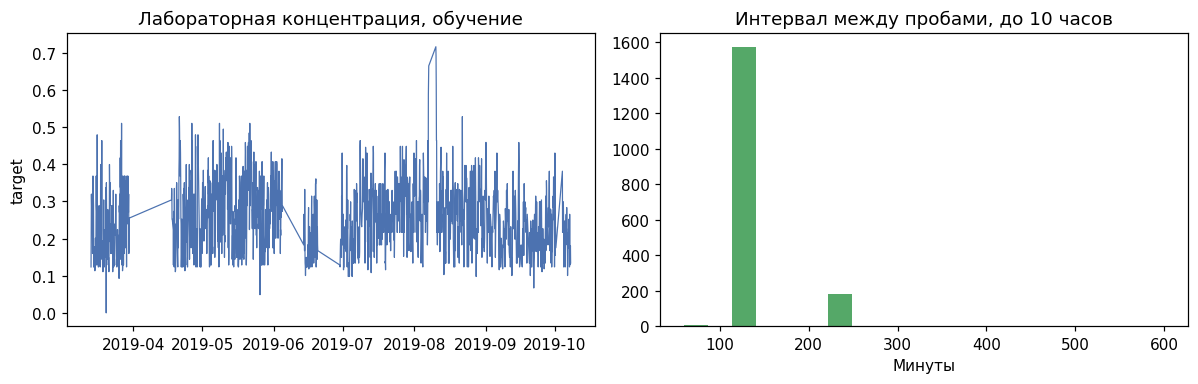

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(lab["datetime"], lab["target"], lw=0.8, color="#4C72B0")
axes[0].set_title("Лабораторная концентрация, обучение")
axes[0].set_ylabel("target")
clipped = step_min[step_min <= 600]
axes[1].hist(clipped, bins=20, color="#55A868")
axes[1].set_title("Интервал между пробами, до 10 часов")
axes[1].set_xlabel("Минуты")
plt.tight_layout()
plt.show()

In [17]:
by_hour = lab.groupby(lab["datetime"].dt.hour)["target"].agg(["mean", "count"])
by_dow = lab.groupby(lab["datetime"].dt.dayofweek)["target"].mean()
print("среднее цели по часу отбора:")
print(by_hour.round(3).to_string())
print("среднее по дню недели, пн=0:", by_dow.round(3).to_string())
print(
    "автокорреляция соседних проб:",
    round(lab["target"].autocorr(1), 3),
    "через одну:",
    round(lab["target"].autocorr(2), 3),
)

среднее цели по часу отбора:
           mean  count
datetime              
1         0.258    163
3         0.260    132
5         0.259    161
6         0.255      1
7         0.261    130
8         0.124      1
9         0.253    158
10        0.187      2
11        0.255    131
13        0.246    161
15        0.257    134
17        0.256    165
19        0.251    135
21        0.240    165
22        0.232      1
23        0.261    133
среднее по дню недели, пн=0: datetime
0    0.253
1    0.252
2    0.257
3    0.264
4    0.254
5    0.250
6    0.252
автокорреляция соседних проб: 0.55 через одну: 0.353


In [18]:
def align(series: pd.Series, when: pd.DatetimeIndex, lag_min: int) -> pd.Series:
    return series.reindex(when - pd.Timedelta(minutes=lag_min))


def corr_at_lag(lag_min: int) -> pd.Series:
    when = pd.DatetimeIndex(lab["datetime"])
    y = lab["target"].to_numpy()
    out = {}
    for column in DENSE:
        x = align(eda_tel[column], when, lag_min).to_numpy()
        mask = np.isfinite(x) & np.isfinite(y)
        out[column] = np.corrcoef(x[mask], y[mask])[0, 1] if mask.sum() > 50 else np.nan
    return pd.Series(out)


lag_grid = [0, 10, 15, 30, 45, 60, 90, 120, 180]
lag_corr = pd.DataFrame({lag: corr_at_lag(lag) for lag in lag_grid})
print("корреляция канала и цели при сдвиге цели назад, минуты")
print("лаг больше нуля: смотрю телеметрию раньше момента пробы")
print(lag_corr.round(3).to_string())

корреляция канала и цели при сдвиге цели назад, минуты
лаг больше нуля: смотрю телеметрию раньше момента пробы
                0      10     15     30     45     60     90     120    180
telemetry_0  -0.187 -0.183 -0.177 -0.171 -0.165 -0.152 -0.118 -0.095 -0.080
telemetry_1  -0.044 -0.040 -0.044 -0.057 -0.049 -0.058 -0.027 -0.007 -0.016
telemetry_2  -0.003 -0.011 -0.011  0.002  0.013  0.008 -0.008 -0.021 -0.003
telemetry_3  -0.118 -0.119 -0.127 -0.179 -0.144 -0.159 -0.104 -0.104 -0.080
telemetry_4  -0.091 -0.077 -0.070 -0.090 -0.101 -0.087 -0.075 -0.049 -0.032
telemetry_5  -0.046 -0.072 -0.071 -0.071 -0.082 -0.076 -0.060 -0.074 -0.062
telemetry_6  -0.082 -0.095 -0.090 -0.108 -0.108 -0.112 -0.077 -0.063 -0.051
telemetry_7  -0.036 -0.045 -0.045 -0.044 -0.046 -0.033 -0.048 -0.063 -0.053
telemetry_8   0.104  0.090  0.089  0.090  0.069  0.096  0.074  0.071  0.058
telemetry_9  -0.122 -0.122 -0.120 -0.121 -0.115 -0.115 -0.119 -0.104 -0.108
telemetry_10 -0.069 -0.071 -0.072 -0.071 -0.071 -0.06

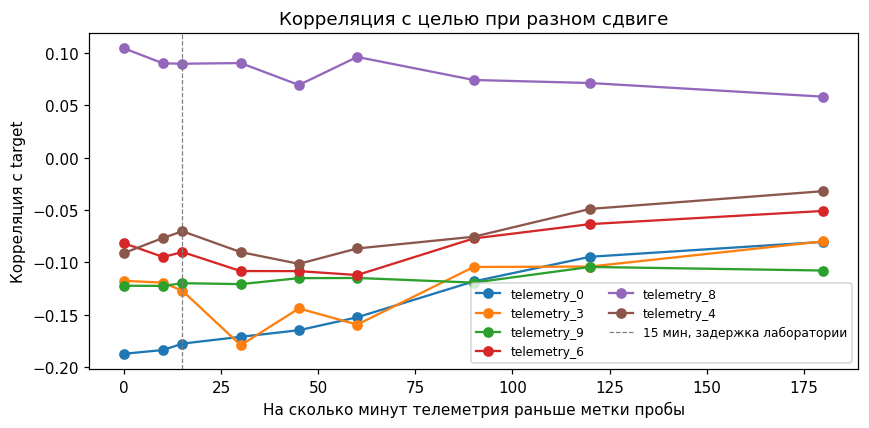

In [19]:
top_channels = lag_corr.abs().max(axis=1).sort_values(ascending=False).head(6).index
fig, ax = plt.subplots(figsize=(8, 4))
for column in top_channels:
    ax.plot(lag_grid, lag_corr.loc[column], marker="o", label=column)
ax.axvline(15, color="gray", ls="--", lw=0.8, label="15 мин, задержка лаборатории")
ax.set_xlabel("На сколько минут телеметрия раньше метки пробы")
ax.set_ylabel("Корреляция с target")
ax.set_title("Корреляция с целью при разном сдвиге")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

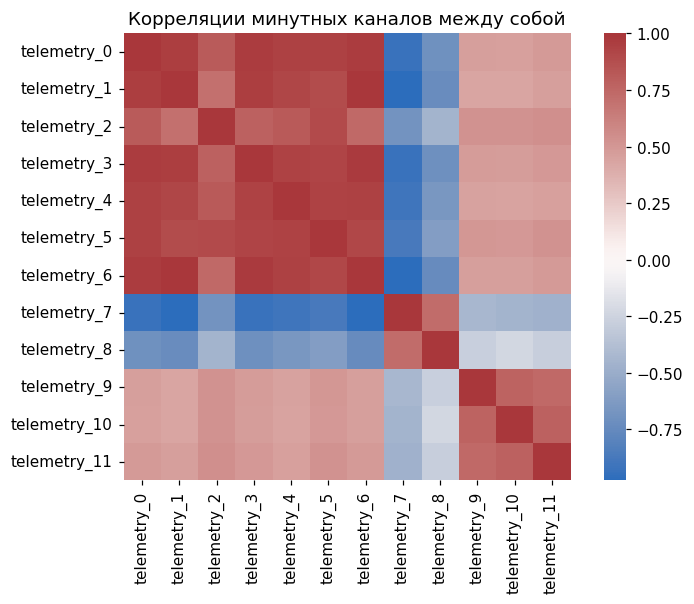

In [20]:
fig, ax = plt.subplots(figsize=(7.2, 5.6))
sns.heatmap(eda_tel[DENSE].corr(), cmap="vlag", center=0, ax=ax, square=True)
ax.set_title("Корреляции минутных каналов между собой")
plt.tight_layout()
plt.show()

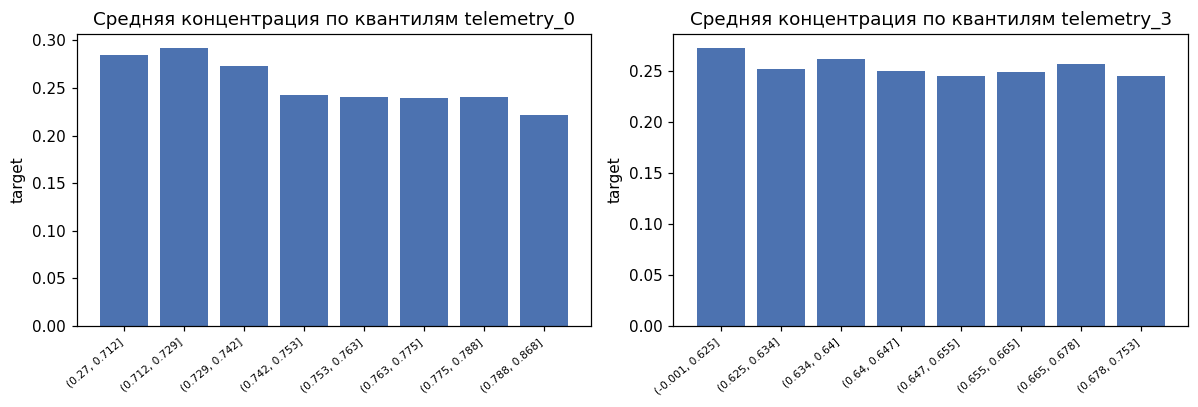

In [21]:
joined = lab.copy()
joined["telemetry_0"] = align(eda_tel["telemetry_0"], pd.DatetimeIndex(lab["datetime"]), 0).to_numpy()
joined["telemetry_3"] = align(eda_tel["telemetry_3"], pd.DatetimeIndex(lab["datetime"]), 0).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, column in zip(axes, ["telemetry_0", "telemetry_3"]):
    part = joined[["target", column]].dropna()
    part["bin"] = pd.qcut(part[column], 8, duplicates="drop")
    means = part.groupby("bin", observed=True)["target"].mean()
    ax.bar(range(len(means)), means.to_numpy(), color="#4C72B0")
    ax.set_xticks(range(len(means)))
    ax.set_xticklabels([str(b) for b in means.index], rotation=40, ha="right", fontsize=7)
    ax.set_title(f"Средняя концентрация по квантилям {column}")
    ax.set_ylabel("target")
plt.tight_layout()
plt.show()

### Вывод по разведке

Минутный ряд без дыр. Повторы одной минуты почти одинаковые, беру среднее. Каналы 0–11 идут каждую минуту. Каналы 12–15 пишутся раз в два часа в чётный час, пустых ячеек около 99%. Это не поломка: держу последнее значение и не заглядываю вперёд. Нули у каналов 1, 3, 4 и 6 слишком частые для выбросов, помечаю их флагом и ничего по IQR не вырезаю. Короткие дырки в 1–2 минуты заполнил, длинные оставил пустыми.

Пробы почти всегда в нечётный час, шаг обычно 120 минут, бывают паузы в несколько суток. Суточного и недельного хода у цели нет. Ноль 20 марта в обучение не беру: следующее маленькое значение около 0.11, похоже на сбой. Связь одного канала с целью слабая, сильнее всего `telemetry_0`, около −0.19. Сдвиг метки на 10–15 минут её не улучшает, значит время в файле — время отбора пробы. Задержку лаборатории учитываю так: замер моложе 15 минут ещё нельзя использовать. Соседние пробы коррелируют на 0.55, поэтому прошлый замер важнее одного канала.

## 2.2. Признаки

Признаки на момент пробы собираю только из того, что к этой минуте уже известно.

Для каналов 0–11:

- значение сейчас;
- лаги 15, 60 и 120 минут;
- средние за 30 и 120 минут;
- за последний час — std, минимум и максимум;
- изменение за час и темп за час. Темп обрезаю на ±200%, чтобы деление на почти ноль не стало отдельным признаком.

Каналы 12–15 входят последним известным значением.

Прошлый лабораторный замер беру, только если ему больше 15 минут и не больше 6 часов. Рядом кладу его возраст в минутах и флаг «свежего замера нет». Флаг нужен линейной модели: иначе пустое место заменится медианой и будет выглядеть как обычная средняя концентрация.

Час и день недели не добавляю. У цели нет суточной и недельной волны, календарь только изобразил бы её.

In [22]:
def build_features(frame: pd.DataFrame) -> pd.DataFrame:
    parts = [frame[DENSE].add_suffix("_now")]
    for lag in LAGS:
        parts.append(frame[DENSE].shift(lag).add_suffix(f"_lag{lag}"))
    parts.append(frame[DENSE].rolling(30, min_periods=15).mean().add_suffix("_mean30"))
    parts.append(frame[DENSE].rolling(120, min_periods=60).mean().add_suffix("_mean120"))
    hour = frame[DENSE].rolling(60, min_periods=30)
    parts.append(hour.std().add_suffix("_std60"))
    parts.append(hour.min().add_suffix("_min60"))
    parts.append(hour.max().add_suffix("_max60"))
    parts.append(frame[DENSE].diff(60).add_suffix("_d60"))
    previous = frame[DENSE].shift(60)
    rate = (frame[DENSE] - previous) / previous.where(previous.abs() > 1e-3)
    parts.append(rate.clip(-2, 2).add_suffix("_rate60"))
    parts.append(frame[SLOW].add_suffix("_slow"))
    for column in ZERO_CHANNELS:
        parts.append((frame[column] == 0).astype(float).rename(f"{column}_is0").to_frame())
    features = pd.concat(parts, axis=1)
    features.index.name = "datetime"
    return features

In [23]:
def last_known_lab(times: np.ndarray, history: pd.Series) -> pd.DataFrame:
    """Последний лабораторный замер: уже должен был прийти и не старше 6 часов."""
    history = history.sort_index()
    h_times = history.index.to_numpy()
    h_vals = history.to_numpy(dtype=float)
    times = np.asarray(times, dtype="datetime64[ns]")
    cutoff = times - np.timedelta64(LAB_DELAY_MIN, "m")
    position = np.searchsorted(h_times, cutoff, side="right") - 1
    value = np.full(len(times), np.nan)
    age = np.full(len(times), np.nan)
    ok = position >= 0
    chosen_time = h_times[position[ok]]
    age_ok = (times[ok] - chosen_time) / np.timedelta64(1, "m")
    fresh = (age_ok >= LAB_DELAY_MIN - 1e-6) & (age_ok <= LAB_MAX_AGE_MIN)
    idx = np.flatnonzero(ok)
    value[idx[fresh]] = h_vals[position[ok][fresh]]
    age[idx[fresh]] = age_ok[fresh]
    finite_age = age[np.isfinite(age)]
    if len(finite_age):
        assert finite_age.min() >= LAB_DELAY_MIN - 1e-6
    return pd.DataFrame({"last_lab": value, "last_lab_age_min": age})

In [24]:
def design_matrix(features: pd.DataFrame, labels: pd.DataFrame, history: pd.Series):
    times = labels["datetime"].to_numpy(dtype="datetime64[ns]")
    matrix = features.reindex(pd.DatetimeIndex(times)).copy()
    known = last_known_lab(times, history)
    matrix["last_lab"] = known["last_lab"].to_numpy()
    matrix["last_lab_age_min"] = known["last_lab_age_min"].to_numpy()
    matrix["last_lab_missing"] = matrix["last_lab"].isna().astype(float)
    valid = matrix["telemetry_0_now"].notna().to_numpy() & np.isfinite(labels["target"].to_numpy())
    matrix = matrix.loc[valid]
    matrix.index = pd.DatetimeIndex(times[valid], name="datetime")
    y = labels["target"].to_numpy()[valid]
    return matrix, y

In [25]:
features = build_features(telemetry)
print("ширина матрицы признаков на минутной сетке, без лаборатории:", features.shape[1])

# Ноль у цели похож на сбой анализа: не кладу его ни в y, ни в прошлые замеры.
train_labels = train_target.loc[train_target["target"] > 0].reset_index(drop=True)
test_labels = test_target.loc[test_target["target"] > 0].reset_index(drop=True)
train_history = train_labels.set_index("datetime")["target"]
test_history = pd.concat([train_history, test_labels.set_index("datetime")["target"]]).sort_index()
test_history = test_history[~test_history.index.duplicated(keep="first")]

X_train_full, y_train_full = design_matrix(features, train_labels, train_history)
X_test, y_test = design_matrix(features, test_labels, test_history)
print("обучающих проб с телеметрией:", len(X_train_full), "тестовых:", len(X_test))
print(
    "доля проб без свежего замера, обучение / тест:",
    round(X_train_full["last_lab_missing"].mean(), 3),
    round(X_test["last_lab_missing"].mean(), 3),
)

ширина матрицы признаков на минутной сетке, без лаборатории: 140
обучающих проб с телеметрией: 1772 тестовых: 318
доля проб без свежего замера, обучение / тест: 0.007 0.006


In [26]:
example_at = X_test.index[10]
print(
    "пример на тесте:",
    example_at,
    "last_lab =",
    round(X_test.loc[example_at, "last_lab"], 4),
    "возраст, мин =",
    X_test.loc[example_at, "last_lab_age_min"],
)

пример на тесте: 2019-10-08 19:00:00 last_lab = 0.1134 возраст, мин = 120.0


last_lab               0.554
telemetry_0_max60     -0.202
telemetry_15_slow      0.189
telemetry_0_now       -0.186
telemetry_0_mean30    -0.181
telemetry_0_lag15     -0.177
telemetry_4_is0        0.168
telemetry_6_max60     -0.164
telemetry_3_max60     -0.159
telemetry_3_lag60     -0.158
telemetry_3_mean120   -0.155
telemetry_0_lag60     -0.152
telemetry_0_mean120   -0.151
telemetry_12_slow     -0.147
telemetry_4_max60     -0.146


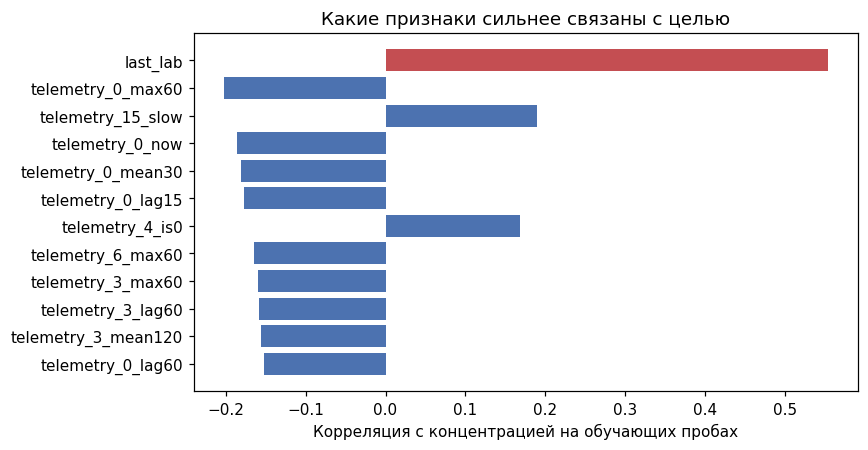

In [27]:
LAB_COLUMNS = ["last_lab", "last_lab_age_min", "last_lab_missing"]
feature_corr = X_train_full.apply(lambda column: column.corr(pd.Series(y_train_full, index=X_train_full.index)))
feature_corr = feature_corr.reindex(feature_corr.abs().sort_values(ascending=False).index)
print(feature_corr.head(15).round(3).to_string())

top = feature_corr.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = ["#C44E52" if name in LAB_COLUMNS else "#4C72B0" for name in top.index]
ax.barh(top.index, top.to_numpy(), color=colors)
ax.set_xlabel("Корреляция с концентрацией на обучающих пробах")
ax.set_title("Какие признаки сильнее связаны с целью")
plt.tight_layout()
plt.show()

In [ ]:
cut = int(len(X_train_full) * 0.8)
X_fit, X_val = X_train_full.iloc[:cut], X_train_full.iloc[cut:]
y_fit, y_val = y_train_full[:cut], y_train_full[cut:]
print("подбор по времени: обучение до", X_fit.index.max(), "хвост с", X_val.index.min(), "проб", len(X_val))

подбор по времени: обучение до 2019-08-24 01:00:00 хвост с 2019-08-24 03:00:00 проб 355


компонент до 95% дисперсии: 35 из 143


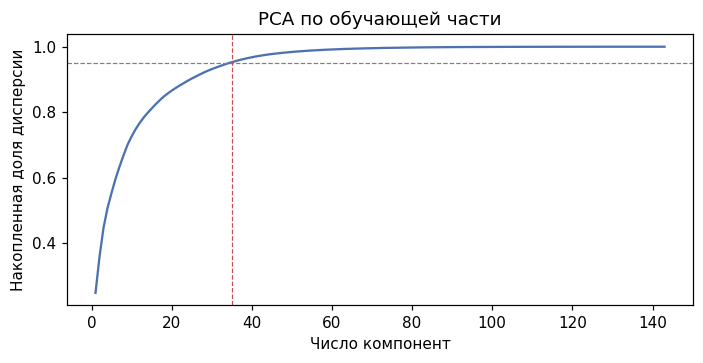

In [29]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
Z_fit = scaler.fit_transform(imputer.fit_transform(X_fit))
Z_val = scaler.transform(imputer.transform(X_val))
_, singular, vt = np.linalg.svd(Z_fit, full_matrices=False)
variance = singular ** 2
variance_share = np.cumsum(variance) / variance.sum()
n95 = int(np.searchsorted(variance_share, 0.95) + 1)
print(f"компонент до 95% дисперсии: {n95} из {Z_fit.shape[1]}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(np.arange(1, len(variance_share) + 1), variance_share, color="#4C72B0")
ax.axhline(0.95, color="gray", ls="--", lw=0.8)
ax.axvline(n95, color="#C44E52", ls="--", lw=0.8)
ax.set_xlabel("Число компонент")
ax.set_ylabel("Накопленная доля дисперсии")
ax.set_title("PCA по обучающей части")
plt.tight_layout()
plt.show()

In [30]:
def ridge_mae(x_train, y_train, x_valid, y_valid, alpha: float) -> float:
    model = Ridge(alpha=alpha)
    model.fit(x_train, y_train)
    return mean_absolute_error(y_valid, model.predict(x_valid))


raw_scores = {alpha: ridge_mae(Z_fit, y_fit, Z_val, y_val, alpha) for alpha in ALPHA_GRID}
best_raw_alpha = min(raw_scores, key=raw_scores.get)
pca_scores = {}
for n_comp in (10, 20, n95):
    p_fit, p_val = Z_fit @ vt[:n_comp].T, Z_val @ vt[:n_comp].T
    best = min(ALPHA_GRID, key=lambda alpha: ridge_mae(p_fit, y_fit, p_val, y_val, alpha))
    pca_scores[n_comp] = (best, ridge_mae(p_fit, y_fit, p_val, y_val, best))

print("ридж на исходных признаках, лучшая MAE хвоста:", round(raw_scores[best_raw_alpha], 4), "alpha", best_raw_alpha)
print("ридж на главных компонентах (число компонент, alpha, MAE):")
for n_comp, (alpha, score) in pca_scores.items():
    print(f"  {n_comp:3d}  alpha {alpha:<6}  MAE {score:.4f}")

ридж на исходных признаках, лучшая MAE хвоста: 0.061 alpha 300
ридж на главных компонентах (число компонент, alpha, MAE):
   10  alpha 1000    MAE 0.0745
   20  alpha 30      MAE 0.0670
   35  alpha 10      MAE 0.0600


### Вывод по признакам

Беру текущий уровень, лаги 15/60/120 минут, среднее, размах и скорость за час, плюс последний замер не старше 6 часов. Всё это уже известно к минуте пробы. Прошлый замер связан с целью сильнее каналов, каналы только поправляют его. Лаги одинаковые у всех каналов и взяты из шага проб, не из перебора на тесте.

PCA до 95% дисперсии — 35 компонент из 143. Ридж на них даёт MAE 0.060 против 0.061 на исходных столбцах. Имя канала при этом пропадает, поэтому оставляю исходные признаки.

## 2.3. Модели

На каждой пробе есть строка признаков и одно число — концентрация. Нужна регрессия. Меток около 1700, а лаги между собой похожи, это надо учитывать.

Беру три модели, все на одной таблице.

- **Ридж.** Прямая зависимость от каналов и прошлого замера. L2 ужимает пачки одинаковых лагов. Коэффициенты после стандартизации можно сравнивать по величине, но из-за похожих столбцов я читаю их по короткой модели ниже, а не по полной матрице.
- **Случайный лес.** Умеет пороги, масштаб не важен. Нормально переживает режим «канал лежит в нуле» и не тянет одну прямую через весь диапазон.
- **Бустинг (HistGradientBoosting).** Тоже нелинейный, ошибки правит по шагам и сам умеет пропуски. Его беру основным, если поправка к прошлому замеру не прямая.

Что не беру и почему.

- **ARIMA / SARIMA только по концентрации.** Она не видит телеметрию, это не датчик печи, а продолжение редких замеров. На паузе в несколько суток ей не на что опереться, а ответ нужен в любую минуту.
- **LSTM и другие сети по минутному окну.** Меток около 1700, окно — сотни минут и 16 каналов. Сеть легко запомнит шум этого периода, а объяснить смене решение будет нечем. Память, которая тут реально видна, уже лежит в лагах и скользящих средних.
- **Prophet.** Ему нужна одна кривая с календарным сезоном. У концентрации суточного хода нет, каналов 16, шаг проб плавает.
- **Классификация и линия между соседними пробами.** Цель — число, не класс. Линия между пробами использует будущий замер, то есть отвечает уже после лаборатории. Оператору нужно число до этого замера.

Параметры выбираю по последним 20% обучающих проб, по времени, без перемешивания. Если перемешать блоки, в прошлое попадёт будущий режим печи. Раннюю остановку бустинга тоже не включаю: она отрезает случайный кусок строк. Когда параметры выбраны, учу модели заново на всём обучении и один раз считаю тест.

Рядом два простых варианта, хуже которых датчик не нужен: всегда писать среднее обучения и повторять последний свежий замер. Если замер старше 6 часов, вместо него подставляю то же среднее.

In [31]:
def point_metrics(y_true, y_pred) -> dict:
    error = np.asarray(y_true) - np.asarray(y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAPE_%": float(np.mean(np.abs(error / np.asarray(y_true))) * 100),
        "WAPE_%": float(np.sum(np.abs(error)) / np.sum(np.abs(y_true)) * 100),
    }


def direction_stats(times: pd.DatetimeIndex, y_true, y_pred, step_min: int = 120) -> dict:
    """Совпал ли знак изменения у факта и прогноза. Беру только пары ровно через 2 часа."""
    times = pd.DatetimeIndex(times)
    delta_t = times.to_series().diff().dt.total_seconds().to_numpy() / 60
    dy = np.diff(y_true, prepend=np.nan)
    dp = np.diff(y_pred, prepend=np.nan)
    regular = delta_t == step_min
    moved = regular & np.isfinite(dy) & (dy != 0)
    agree = np.sign(dy[moved]) == np.sign(dp[moved])
    pair = regular & np.isfinite(dy) & np.isfinite(dp)
    if pair.sum() > 5 and np.std(dy[pair]) > 1e-12 and np.std(dp[pair]) > 1e-12:
        corr = float(np.corrcoef(dy[pair], dp[pair])[0, 1])
    else:
        corr = np.nan
    return {
        "direction_acc": float(np.mean(agree)) if moved.any() else np.nan,
        "direction_n": int(moved.sum()),
        "delta_corr": float(corr),
    }

In [32]:
def make_ridge(alpha: float) -> Pipeline:
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha)),
    ])


def make_forest() -> Pipeline:
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=14,
            min_samples_leaf=4,
            max_features="sqrt",
            n_jobs=4,
            random_state=SEED,
        )),
    ])


def make_boosting(max_depth: int) -> HistGradientBoostingRegressor:
    return HistGradientBoostingRegressor(
        max_depth=max_depth,
        learning_rate=0.05,
        max_iter=350,
        min_samples_leaf=20,
        l2_regularization=0.1,
        early_stopping=False,
        random_state=SEED,
    )


def persistence(frame: pd.DataFrame, fallback: float) -> np.ndarray:
    return frame["last_lab"].fillna(fallback).to_numpy()

In [33]:
ridge_val = {alpha: ridge_mae(Z_fit, y_fit, Z_val, y_val, alpha) for alpha in ALPHA_GRID}
alpha_star = min(ridge_val, key=ridge_val.get)
print("MAE риджа на хвосте по alpha:")
print(pd.Series(ridge_val).round(4).to_string())
print("выбран alpha", alpha_star)

MAE риджа на хвосте по alpha:
0.3       0.0663
1.0       0.0659
3.0       0.0653
10.0      0.0642
30.0      0.0629
100.0     0.0616
300.0     0.0610
1000.0    0.0621
выбран alpha 300


In [34]:
depth_scores = {}
for depth in (3, 6):
    model = make_boosting(depth)
    model.fit(X_fit, y_fit)
    depth_scores[depth] = mean_absolute_error(y_val, model.predict(X_val))
print("MAE бустинга на хвосте по глубине:", {k: round(v, 4) for k, v in depth_scores.items()})
depth_star = min(depth_scores, key=depth_scores.get)
print("выбрана глубина", depth_star)

MAE бустинга на хвосте по глубине: {3: 0.0573, 6: 0.06}
выбрана глубина 3


In [35]:
mean_baseline = float(y_fit.mean())
rows = [
    {"model": "среднее обучения", **point_metrics(y_val, np.full_like(y_val, mean_baseline))},
    {"model": "прошлый замер", **point_metrics(y_val, persistence(X_val, mean_baseline))},
]
candidates = {
    "ridge": make_ridge(alpha_star),
    "random_forest": make_forest(),
    "boosting": make_boosting(depth_star),
}
for name, model in candidates.items():
    started = time.perf_counter()
    model.fit(X_fit, y_fit)
    fit_s = time.perf_counter() - started
    started = time.perf_counter()
    pred = model.predict(X_val)
    pred_s = time.perf_counter() - started
    rows.append({"model": name, **point_metrics(y_val, pred), "fit_s": fit_s, "predict_s": pred_s})

# Та же модель без прошлого замера: это датчик или просто память лаборатории.
tele_columns = [c for c in X_fit.columns if c not in LAB_COLUMNS]
boost_tele = make_boosting(depth_star)
boost_tele.fit(X_fit[tele_columns], y_fit)
rows.append({"model": "бустинг без замера", **point_metrics(y_val, boost_tele.predict(X_val[tele_columns]))})

val_table = pd.DataFrame(rows).set_index("model")
print("хвост обучения", X_val.index.min(), "→", X_val.index.max())
print(val_table.round(4).to_string())

хвост обучения 2019-08-24 03:00:00 → 2019-10-07 21:00:00
                       MAE    RMSE   MAPE_%   WAPE_%   fit_s  predict_s
model                                                                  
среднее обучения    0.0704  0.0843  39.9250  31.1475     NaN        NaN
прошлый замер       0.0636  0.0817  30.6347  28.1504     NaN        NaN
ridge               0.0610  0.0750  34.3138  27.0078  0.0178     0.0013
random_forest       0.0625  0.0774  34.9011  27.6848  0.5089     0.0243
boosting            0.0573  0.0726  29.1124  25.3788  0.6002     0.0113
бустинг без замера  0.0688  0.0852  36.7165  30.4558     NaN        NaN


### Вывод по выбору моделей

Ридж, лес и бустинг закрывают разные случаи: прямая, пороги и пошаговое исправление ошибки. Все три отвечают в любую минуту. ARIMA, LSTM и Prophet не беру: цель редкая, каналов много, сезона нет, меток мало для сети по минутам. Alpha и глубину выбираю только на хвосте обучения. Рядом с моделями всегда считаю среднее и повтор прошлого замера, иначе легко принять память концентрации за качество датчика.

## 2.3. Оценка качества

Модели заново учу на всех обучающих пробах, параметры уже выбраны. Цифры ниже — тестовый файл.

MAE и RMSE — ошибка в единицах концентрации. MAPE — средняя ошибка в процентах от факта. WAPE — сумма модулей ошибки, делённая на сумму модулей факта. WAPE спокойнее MAPE, если какая-то проба близка к нулю. Нулевую пробу я и так убрал.

Направление считаю только между соседними пробами, которые стоят ровно через 120 минут. Сравниваю знак изменения факта и знак изменения прогноза. Пары через пропущенную смену сюда не беру: там смешаны простой лаборатории и ход печи.

Дальше остатки, важность и AIC/BIC. AIC и BIC считаю только для линейных моделей и на одних и тех же строках. У леса и бустинга такой функции правдоподобия нет, их AIC с риджем сравнивать нельзя.

In [36]:
final_models = {
    "ridge": make_ridge(alpha_star),
    "random_forest": make_forest(),
    "boosting": make_boosting(depth_star),
}
test_rows = []
predictions = {}
timings = {}
mean_full = float(y_train_full.mean())

test_rows.append({"model": "среднее обучения", **point_metrics(y_test, np.full_like(y_test, mean_full, dtype=float))})
predictions["среднее обучения"] = np.full_like(y_test, mean_full, dtype=float)
test_rows.append({"model": "прошлый замер", **point_metrics(y_test, persistence(X_test, mean_full))})
predictions["прошлый замер"] = persistence(X_test, mean_full)

for name, model in final_models.items():
    started = time.perf_counter()
    model.fit(X_train_full, y_train_full)
    fit_s = time.perf_counter() - started
    started = time.perf_counter()
    pred = model.predict(X_test)
    pred_s = time.perf_counter() - started
    final_models[name] = model
    predictions[name] = pred
    timings[name] = (fit_s, pred_s)
    test_rows.append({"model": name, **point_metrics(y_test, pred), "fit_s": fit_s, "predict_s": pred_s})

test_table = pd.DataFrame(test_rows).set_index("model")
print(test_table.round(4).to_string())

                     MAE    RMSE   MAPE_%   WAPE_%   fit_s  predict_s
model                                                                
среднее обучения  0.0804  0.0920  48.5008  38.3445     NaN        NaN
прошлый замер     0.0597  0.0803  29.9468  28.4820     NaN        NaN
ridge             0.0524  0.0677  28.8190  24.9832  0.0203     0.0012
random_forest     0.0575  0.0716  32.0444  27.4275  0.5941     0.0275
boosting          0.0531  0.0696  28.4917  25.3031  0.5097     0.0100


In [37]:
boost_tele_full = make_boosting(depth_star)
boost_tele_full.fit(X_train_full[tele_columns], y_train_full)
pred_tele = boost_tele_full.predict(X_test[tele_columns])
predictions["бустинг без замера"] = pred_tele
extra = pd.DataFrame([{"model": "бустинг без замера", **point_metrics(y_test, pred_tele)}]).set_index("model")
test_table = pd.concat([test_table, extra])
print(test_table.loc[["бустинг без замера"]].round(4).to_string())

                       MAE    RMSE   MAPE_%   WAPE_%  fit_s  predict_s
model                                                                 
бустинг без замера  0.0633  0.0783  35.1083  30.1862    NaN        NaN


In [38]:
direction_rows = []
for name, pred in predictions.items():
    direction_rows.append({"model": name, **direction_stats(X_test.index, y_test, pred)})
direction_table = pd.DataFrame(direction_rows).set_index("model")
print("направление на шаге 120 минут:")
print(direction_table.round(3).to_string())

направление на шаге 120 минут:
                    direction_acc  direction_n  delta_corr
model                                                     
среднее обучения            0.000          299         NaN
прошлый замер               0.351          299      -0.386
ridge                       0.478          299      -0.167
random_forest               0.528          299      -0.047
boosting                    0.502          299      -0.203
бустинг без замера          0.569          299       0.118


In [39]:
# Графики строю по модели, которую выбрал ещё до теста.
val_choice = val_table.loc[["ridge", "random_forest", "boosting"], "MAE"].idxmin()
test_choice = test_table.loc[["ridge", "random_forest", "boosting"], "MAE"].idxmin()
best_name = val_choice
best_pred = predictions[best_name]
print("модель по хвосту обучения:", val_choice)
print("меньшая MAE уже на тесте:", test_choice)

модель по хвосту обучения: boosting
меньшая MAE уже на тесте: ridge


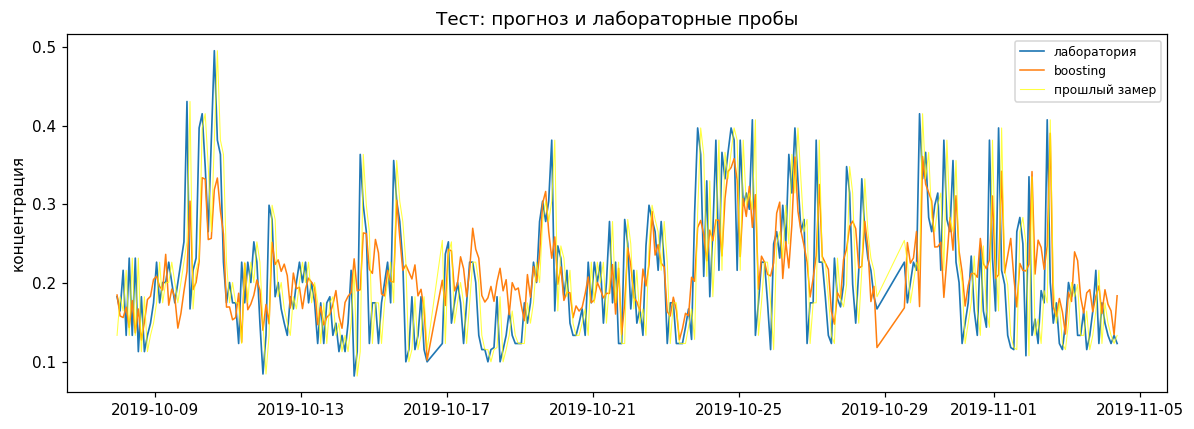

In [54]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(X_test.index, y_test,  lw=1.1, label="лаборатория")
ax.plot(X_test.index, best_pred, lw=1.0, label=best_name)
ax.plot(X_test.index, predictions["прошлый замер"], color="yellow", lw=0.7, alpha=0.75, label="прошлый замер")
ax.set_title("Тест: прогноз и лабораторные пробы")
ax.set_ylabel("концентрация")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

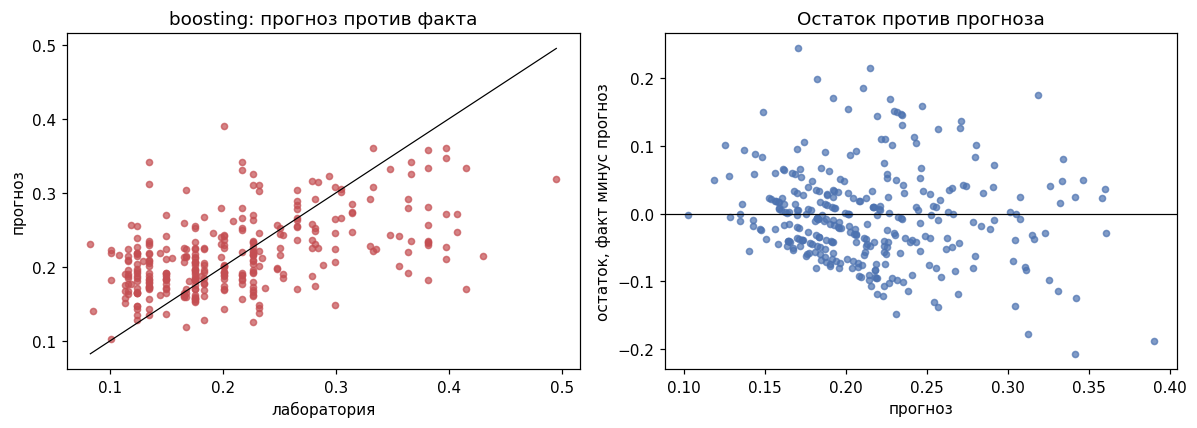

In [41]:
resid = y_test - best_pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, best_pred, s=16, alpha=0.7, color="#C44E52")
limits = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[0].plot(limits, limits, color="black", lw=0.8)
axes[0].set_xlabel("лаборатория")
axes[0].set_ylabel("прогноз")
axes[0].set_title(f"{best_name}: прогноз против факта")
axes[1].scatter(best_pred, resid, s=16, alpha=0.7, color="#4C72B0")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xlabel("прогноз")
axes[1].set_ylabel("остаток, факт минус прогноз")
axes[1].set_title("Остаток против прогноза")
plt.tight_layout()
plt.show()

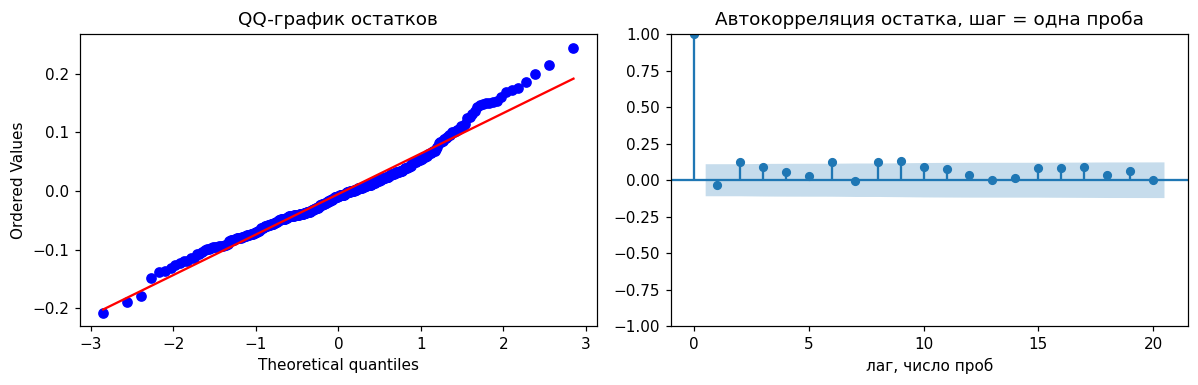

Шапиро–Уилк p=0.000 (первые 318 остатков), Харке–Бера p=7.39e-07
Дарбин–Уотсон 2.056
Бройш–Паган по прогнозу: LM=13.67, p=0.000217


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
stats.probplot(resid, dist="norm", plot=axes[0])
axes[0].set_title("QQ-график остатков")
plot_acf(resid, lags=20, ax=axes[1], title="")
axes[1].set_title("Автокорреляция остатка, шаг = одна проба")
axes[1].set_xlabel("лаг, число проб")
plt.tight_layout()
plt.show()

shapiro_n = min(len(resid), 500)
shapiro_p = stats.shapiro(resid[:shapiro_n]).pvalue
jarque_p = stats.jarque_bera(resid).pvalue
dw = durbin_watson(resid)
bp_stat, bp_p, _, _ = het_breuschpagan(resid, sm.add_constant(best_pred))
print(f"Шапиро–Уилк p={shapiro_p:.3f} (первые {shapiro_n} остатков), Харке–Бера p={jarque_p:.3g}")
print(f"Дарбин–Уотсон {dw:.3f}")
print(f"Бройш–Паган по прогнозу: LM={bp_stat:.2f}, p={bp_p:.3g}")

In [43]:
# Изменение за час = уровень минус лаг, в OLS вместе их не кладу.
short_cols = [
    "last_lab",
    "telemetry_0_now",
    "telemetry_0_lag60",
    "telemetry_3_now",
    "telemetry_3_lag60",
    "telemetry_9_now",
    "telemetry_8_now",
    "telemetry_6_is0",
    "telemetry_15_slow",
]
short = X_train_full[short_cols].replace([np.inf, -np.inf], np.nan).dropna()
y_short = pd.Series(y_train_full, index=X_train_full.index).loc[short.index]
print(f"OLS на полных строках: {len(short)} из {len(X_train_full)}")

scaler_short = StandardScaler()
Z_short = pd.DataFrame(scaler_short.fit_transform(short), index=short.index, columns=short.columns)
ols_anchor = sm.OLS(y_short, sm.add_constant(Z_short[["last_lab"]])).fit()
ols_full = sm.OLS(y_short, sm.add_constant(Z_short)).fit()
lr_stat, lr_p, lr_df = ols_full.compare_lr_test(ols_anchor)
print(f"только прошлый замер:     AIC {ols_anchor.aic:.1f}   BIC {ols_anchor.bic:.1f}   R2 {ols_anchor.rsquared:.3f}")
print(f"замер и каналы:   AIC {ols_full.aic:.1f}   BIC {ols_full.bic:.1f}   R2 {ols_full.rsquared:.3f}")
print(f"LR против модели из одного замера: stat {lr_stat:.1f}, df {lr_df:.0f}, p {lr_p:.3g}")
print(f"Дарбин–Уотсон короткой модели {durbin_watson(ols_full.resid):.3f}")

OLS на полных строках: 1760 из 1772
только прошлый замер:     AIC -4068.7   BIC -4057.8   R2 0.307
замер и каналы:   AIC -4198.0   BIC -4143.2   R2 0.361
LR против модели из одного замера: stat 145.2, df 8, p 1.93e-27
Дарбин–Уотсон короткой модели 2.009


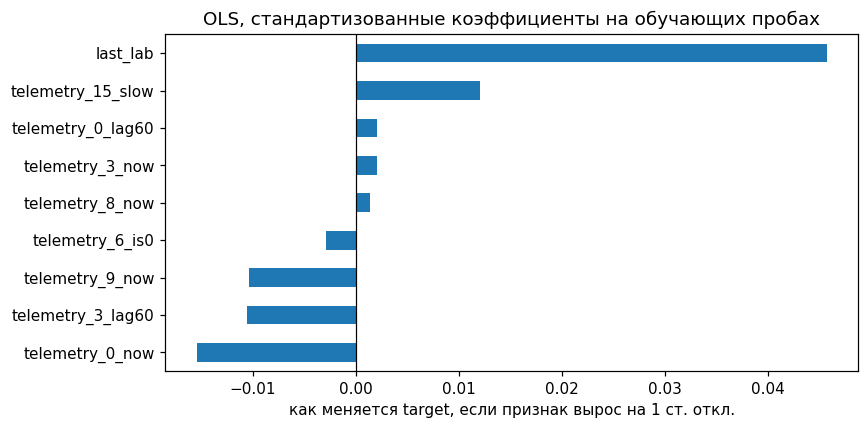

In [55]:
coef = ols_full.params.drop("const").sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
coef.plot(kind="barh", ax=ax)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("OLS, стандартизованные коэффициенты на обучающих пробах")
ax.set_xlabel("как меняется target, если признак вырос на 1 ст. откл.")
plt.tight_layout()
plt.show()

In [45]:
vif = pd.Series(
    [variance_inflation_factor(sm.add_constant(Z_short).to_numpy(), i + 1) for i in range(Z_short.shape[1])],
    index=Z_short.columns,
).sort_values(ascending=False)
print("VIF короткого списка:")
print(vif.round(2).to_string())
print("время обучения и прогноза на тесте, секунды:")
for name, (fit_s, pred_s) in timings.items():
    print(f"  {name:16s}  fit {fit_s:.3f}   predict {pred_s:.4f}")

VIF короткого списка:
telemetry_0_now      4.35
telemetry_0_lag60    4.09
telemetry_3_now      2.18
telemetry_3_lag60    1.89
telemetry_6_is0      1.53
telemetry_9_now      1.15
telemetry_8_now      1.13
last_lab             1.08
telemetry_15_slow    1.08
время обучения и прогноза на тесте, секунды:
  ridge             fit 0.020   predict 0.0012
  random_forest     fit 0.594   predict 0.0275
  boosting          fit 0.510   predict 0.0100


In [46]:
perm_frames = []
for name in ["ridge", "random_forest", "boosting"]:
    result = permutation_importance(
        final_models[name],
        X_test,
        y_test,
        n_repeats=8,
        random_state=SEED,
        scoring="neg_mean_absolute_error",
        n_jobs=4,
    )
    perm_frames.append(pd.DataFrame({
        "feature": X_test.columns,
        "mae_increase": result.importances_mean,
        "model": name,
    }))
importance = pd.concat(perm_frames, ignore_index=True)
top_features = importance.groupby("feature")["mae_increase"].mean().sort_values(ascending=False).head(12).index
pivot = (
    importance[importance["feature"].isin(top_features)]
    .pivot(index="feature", columns="model", values="mae_increase")
    .loc[top_features]
)
print(pivot.round(4).to_string())

model                boosting  random_forest   ridge
feature                                             
last_lab               0.0121         0.0039  0.0109
telemetry_15_slow      0.0006         0.0003  0.0008
telemetry_0_lag120     0.0006         0.0000  0.0004
telemetry_6_max60      0.0001         0.0001  0.0004
telemetry_0_min60      0.0001         0.0003  0.0001
telemetry_6_lag60      0.0000         0.0001  0.0004
telemetry_0_mean30     0.0002         0.0001  0.0002
telemetry_6_mean120    0.0000         0.0002  0.0003
telemetry_0_now       -0.0003         0.0003  0.0005
telemetry_3_lag15      0.0003         0.0000  0.0001
telemetry_0_rate60     0.0001         0.0001  0.0002
telemetry_6_now        0.0001        -0.0001  0.0002


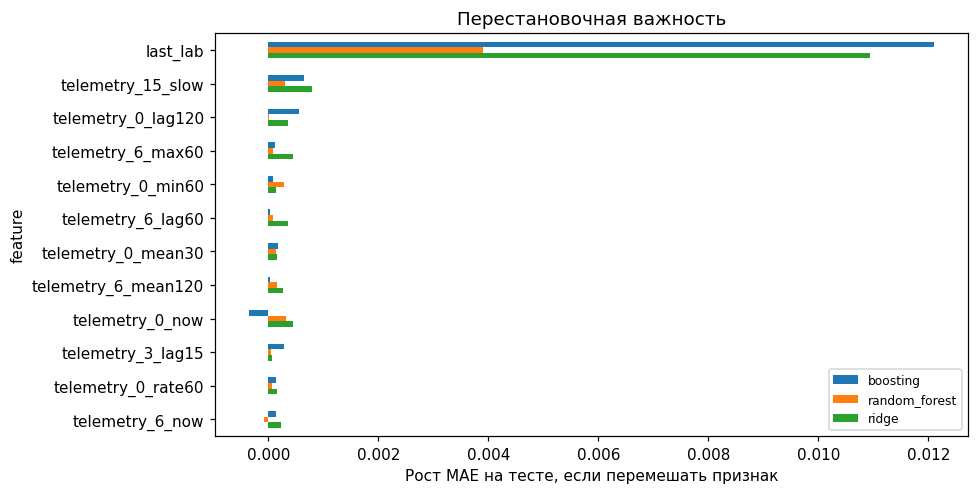

In [47]:
fig, ax = plt.subplots(figsize=(9, 4.6))
pivot.plot(kind="barh", ax=ax)
ax.invert_yaxis()
ax.set_xlabel("Рост MAE на тесте, если перемешать признак")
ax.set_title("Перестановочная важность")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [48]:
explainer = shap.Explainer(final_models["boosting"])
shap_values = explainer(X_test)
mean_abs = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_test.columns)
mean_abs = mean_abs.sort_values(ascending=False).head(12)
print("средний |SHAP| бустинга:")
print(mean_abs.round(4).to_string())

средний |SHAP| бустинга:
last_lab              0.0331
telemetry_12_slow     0.0091
telemetry_15_slow     0.0081
telemetry_0_max60     0.0051
telemetry_11_std60    0.0050
telemetry_0_now       0.0049
telemetry_0_min60     0.0038
telemetry_10_std60    0.0036
telemetry_9_now       0.0032
telemetry_1_lag120    0.0030
telemetry_0_mean30    0.0028
telemetry_3_min60     0.0028


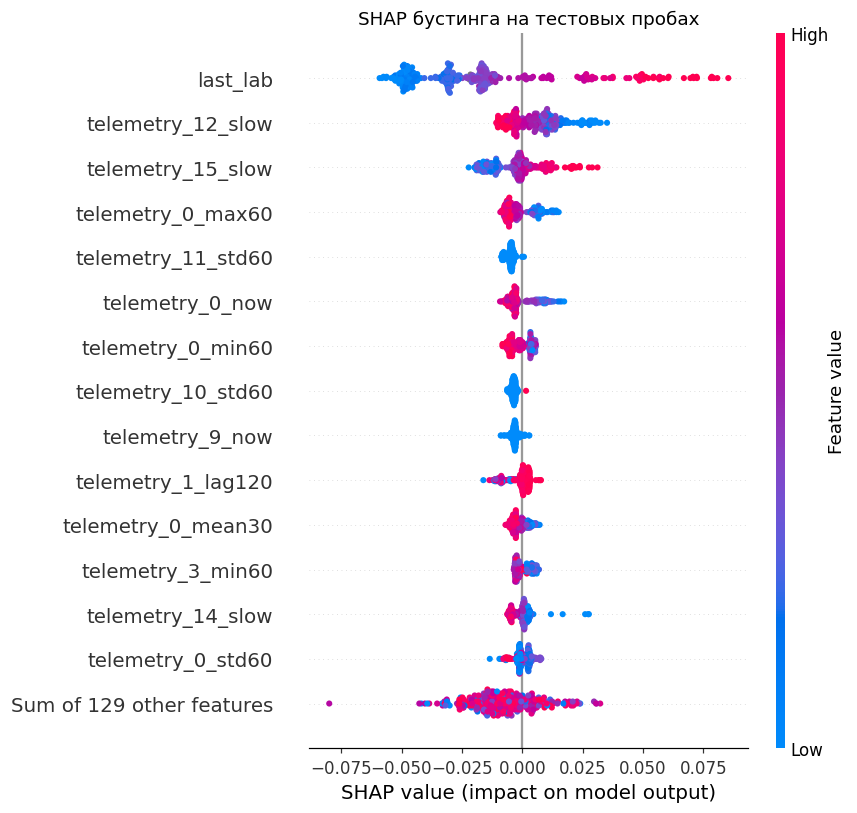

In [49]:
fig = plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP бустинга на тестовых пробах")
plt.tight_layout()
plt.show()

### Вывод по качеству

На тесте планка — повтор прошлого замера, MAE 0.060. Константа хуже, 0.080: осенью уровень уже другой. Ридж 0.052, бустинг 0.053, лес 0.058. Для замены лаборатории это грубо (WAPE около 25%), но между пробами лучше, чем писать старое значение. По хвосту обучения выбран бустинг. На тесте ридж лучше на 0.0007, параметры из-за этого не меняю. Бустинг без замера даёт 0.063: одной телеметрии мало, рабочий вариант — поправка к свежему замеру.

Знак шага за два часа модели берут примерно как монетка (0.48–0.53). Повтор замера угадывает знак только в 35%, потому что после роста чаще идёт спад. Смотреть стоит уровень, не стрелку.

Остатки бустинга не нормальные. Дарбин–Уотсон 2.06, соседние остатки не связаны. Бройш–Паган p ≈ 0.0002, разброс ошибки зависит от уровня. По важности почти всё держит `last_lab`: если его перемешать, MAE растёт на 0.01, один лаг почти ничего не двигает, потому что рядом есть похожие столбцы. SHAP после замера выделяет каналы 12, 15 и часовой максимум `telemetry_0`. Это связь, не совет крутить канал.

Короткая OLS: один замер даёт R² 0.31, с каналами 0.36. AIC −4198 против −4069, p около 10⁻²⁷, VIF не выше 4.4. Каналы добавляют немного, не шум. К лесу и бустингу AIC не прикладываю. Учатся все три меньше секунды.

## 2.4. Что из этого следует

Датчик не заменяет лабораторию, а оценивает концентрацию между пробами. На тесте MAE падает с 0.060 у повтора замера до 0.052–0.053. Если замера не было больше 6 часов, старое значение выключаю: лучше пусто, чем полусуточной давности число. Тогда ошибка ближе к 0.063.

Смотреть уровень, обычная ошибка около 0.05. Знак маленького шага ненадёжный. Важность канала — не инструкция его крутить: имена не подписаны, и оператор мог уже менять режим. Если лаборатория молчит или каналы 1, 3, 4, 6 в нуле, доверять оценке меньше. Ридж и бустинг считаются быстрее секунды и на тесте почти одинаковые.

Имена каналов неизвестны, тест — один осенний месяц. Ноль 20 марта я выкинул как сбой. Если такой ноль на заводе нормальный, правило надо вернуть. Печью модель не управляет.